In [ ]:
import os
import random
import numpy as np
import pandas as pd
import nibabel as nib
from sklearn.model_selection import StratifiedKFold, train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')
import time
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

In [ ]:
#Mount Google Drive to access our dataset stored there instead of uploading files repeatedly
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Define the base directory where our Alzheimer's disease neuroimaging dataset is stored
BASE_DIR = '/content/drive/MyDrive/Final_Dataset1'

#Define folder structure based on our dataset organization:
# - Modality types: MRI, PET, co-registered (coreg)
# - Patient classes: Alzheimer's Disease (ad) vs Control Normal (cn)
# - Data augmentation status: original vs augmented

folders = [
    'original_mri_ad', 'original_mri_cn',
    'augmented_mri_ad', 'augmented_mri_cn',
    'original_pet_ad', 'original_pet_cn',
    'augmented_pet_ad', 'augmented_pet_cn',
    'coreg_ad_augmented', 'coreg_ad_original',
    'coreg_cn_augmented', 'coreg_cn_original'
]


In [ ]:
#Load neuroimaging data from NIfTI format which is the standard for brain imaging
def load_nifti_file(file_path):
    try:
        img = nib.load(file_path)
        #Convert to numpy array for analysis since we need numerical access to voxel values
        data = img.get_fdata()
        #Some scans might have time as 4th dimension; we only need spatial data for this analysis
        if len(data.shape) == 4:
            data = data[:, :, :, 0]
        return data, img.header
    except Exception as e:
        print(f"Error loading {file_path}: {e}")
        return None, None

In [ ]:
#Build a catalogue of dataset entries to streamline loading, validation, and analysis without repeatedly scanning directories.
def datasetCatalogue(base_dir, folders):
    catalogue = []

    for folder in folders:
        folder_path = os.path.join(base_dir, folder)
        if not os.path.exists(folder_path):
        #Skip folders that don't exist to allow flexible folder management and avoid runtime errors.
            continue

        is_augmented = 'augmented' in folder #Identify augmented data early to enable separate evaluation if needed.
        is_coregistered = 'coreg' in folder  #Identify co-registered scans because they have different preprocessing assumptions.

        if is_coregistered:
            modality = 'coreg' #Treat co-registered data as a distinct modality for better downstream handling.
            label = 1 if 'ad' in folder else 0 #Infer labels from folder naming convention to avoid manual annotation.
        else:
            modality = 'mri' if 'mri' in folder else 'pet' #Default to standard modalities unless otherwise indicated.
            label = 1 if 'ad' in folder else 0


        nifti_files = [f for f in os.listdir(folder_path) if f.endswith('.nii.gz')]

        for nifti_file in nifti_files:
            file_path = os.path.join(folder_path, nifti_file)

            try:
                img = nib.load(file_path)
                shape = img.shape
                spacing = img.header.get_zooms()
            except Exception as e:
              #Continue processing other files even if some files are corrupt or unreadable, ensuring maximum dataset is used
                print(f"Error looking at {file_path}: {e}")
                continue

            #Consolidate relevant metadata to allow flexible querying, stratification, and data quality analysis later.
            catalogue.append({'file_path': file_path, 'filename': nifti_file, 'folder': folder, 'modality': modality, 'label': label, 'is_augmented': is_augmented, 'is_coregistered': is_coregistered, 'shape': shape,'spacing': spacing})

    df = pd.DataFrame(catalogue)
    return df

catalogue_df = datasetCatalogue(BASE_DIR, folders)

#Provide quick dataset health checks to detect class imbalance, missing modalities, or preprocessing issues early.
print(f"Total files: {len(catalogue_df)}")
print(f"MRI files: {len(catalogue_df[catalogue_df['modality'] == 'mri'])}")
print(f"PET files: {len(catalogue_df[catalogue_df['modality'] == 'pet'])}")
print(f"Co-registered files: {len(catalogue_df[catalogue_df['modality'] == 'coreg'])}")
print(f"AD samples: {len(catalogue_df[catalogue_df['label'] == 1])}")
print(f"CN samples: {len(catalogue_df[catalogue_df['label'] == 0])}")
print(f"Original samples: {len(catalogue_df[catalogue_df['is_augmented'] == False])}")
print(f"Augmented samples: {len(catalogue_df[catalogue_df['is_augmented'] == True])}")


print("\nShape distribution:")
print(catalogue_df.groupby(['modality', 'shape']).size())

Total files: 1026
MRI files: 342
PET files: 342
Co-registered files: 342
AD samples: 432
CN samples: 594
Original samples: 513
Augmented samples: 513

Shape distribution:
modality  shape             
coreg     (128, 128, 128)       342
mri       (128, 128, 128)       342
pet       (128, 128, 128)       340
          (128, 128, 128, 4)      2
dtype: int64


In [ ]:
#Split the dataset into training, validation, and test sets while preserving label balance and ensuring reproducibility across splits.
def datasetSplitting(catalogue_df, test_size=0.2, val_size=0.15, random_state=42):

    #Use empty DataFrames to allow collection of splits across modalities
    train_df = pd.DataFrame()
    val_df = pd.DataFrame()
    test_df = pd.DataFrame()

    #Process each modality separately to avoid introducing modality bias during train/val/test splitting.
    for modality in ['mri', 'pet', 'coreg']:

        modality_df = catalogue_df[catalogue_df['modality'] == modality]  #Isolate modality-specific samples to treat structural and functional data appropriately.
        original_df = modality_df[~modality_df['is_augmented']]            #Only split original (non-augmented) data to maintain fair and unbiased validation and test sets.
        augmented_df = modality_df[modality_df['is_augmented']]            #Augmented data is reserved for training to enrich learning without contaminating evaluation.

        #Initial split to separate out a fixed percentage of the data for unbiased testing.
        train_val_df, test_mod_df = train_test_split(original_df, test_size=test_size, random_state=random_state, stratify=original_df['label'])  #Maintain the class ratio across splits to prevent skewed evaluation.

        #Adjust validation size relative to the remaining train_val pool after test samples have been removed.
        adjusted_val_size = val_size / (1 - test_size)

        #Secondary split to carve out a validation set from the remaining data, again enforcing class balance.
        train_mod_df, val_mod_df = train_test_split(train_val_df, test_size=adjusted_val_size, random_state=random_state, stratify=train_val_df['label'])

        #Augmented samples are intentionally injected into the training set only to improve model generalisation without biasing validation or test results.
        train_mod_df = pd.concat([train_mod_df, augmented_df])

        #Merge splits from each modality to construct the complete training, validation, and test datasets.
        train_df = pd.concat([train_df, train_mod_df])
        val_df = pd.concat([val_df, val_mod_df])
        test_df = pd.concat([test_df, test_mod_df])

    return train_df, val_df, test_df

train_df, val_df, test_df = datasetSplitting(catalogue_df)

#Provide quick visibility into label balance to detect possible stratification or split errors early.
print(f"Training set: {len(train_df)} files ({len(train_df[train_df['label'] == 1])} AD, {len(train_df[train_df['label'] == 0])} CN)")
print(f"Validation set: {len(val_df)} files ({len(val_df[val_df['label'] == 1])} AD, {len(val_df[val_df['label'] == 0])} CN)")
print(f"Test set: {len(test_df)} files ({len(test_df[test_df['label'] == 1])} AD, {len(test_df[test_df['label'] == 0])} CN)")

#Check the distribution of modalities per split to verify no modality has been inadvertently excluded or overrepresented.
print("\nModality distribution in training set:")
print(train_df.groupby(['modality', 'label']).size())
print("\nModality distribution in validation set:")
print(val_df.groupby(['modality', 'label']).size())
print("\nModality distribution in test set:")
print(test_df.groupby(['modality', 'label']).size())


Training set: 843 files (354 AD, 489 CN)
Validation set: 78 files (33 AD, 45 CN)
Test set: 105 files (45 AD, 60 CN)

Modality distribution in training set:
modality  label
coreg     0        163
          1        118
mri       0        163
          1        118
pet       0        163
          1        118
dtype: int64

Modality distribution in validation set:
modality  label
coreg     0        15
          1        11
mri       0        15
          1        11
pet       0        15
          1        11
dtype: int64

Modality distribution in test set:
modality  label
coreg     0        20
          1        15
mri       0        20
          1        15
pet       0        20
          1        15
dtype: int64


In [ ]:
#Create a custom dataset class to manage loading, preprocessing, and batching of NIfTI medical imaging data.
class NIfTIDataset(Dataset):
    def __init__(self, dataframe, modality=None, transform=None):

        self.transform = transform

        #Filter the dataset by modality if specified to allow flexibility in training modality-specific models.
        if modality:
            self.data = dataframe[dataframe['modality'] == modality].reset_index(drop=True)
        else:
            self.data = dataframe.reset_index(drop=True)

    def __len__(self):
        #Return the total number of samples to integrate seamlessly with PyTorch DataLoader.
        return len(self.data)

    def __getitem__(self, idx):
        file_path = self.data.iloc[idx]['file_path']
        label = self.data.iloc[idx]['label']
        modality = self.data.iloc[idx]['modality']

        scan_data, _ = load_nifti_file(file_path)  #Load the NIfTI file and ignore metadata since only voxel data is required.

        scan_data = scan_data[np.newaxis, :, :, :]  #Explicitly add a channel dimension to match PyTorch CNN input expectations.

        scan_tensor = torch.from_numpy(scan_data.astype(np.float32))  #Convert scan data to a float32 tensor for numerical stability.

        if self.transform:
            scan_tensor = self.transform(scan_tensor)  #Apply optional data transformations like normalisation or augmentation.

        #Return a dictionary for flexible access to image, label, file path, and modality during model training or evaluation.
        return {'image': scan_tensor, 'label': torch.tensor(label, dtype=torch.long), 'path': file_path, 'modality': modality}


In [ ]:
#Create dataloaders for MRI, PET, and co-registered datasets to streamline batch processing and ensure consistent data feeding during training and evaluation.
def createDataloaders(train_df, val_df, test_df, batch_size=4):

    #Create separate datasets per modality to allow independent model training or evaluation on MRI, PET, or co-registered data.
    train_mri_dataset = NIfTIDataset(train_df, modality='mri')
    val_mri_dataset = NIfTIDataset(val_df, modality='mri')
    test_mri_dataset = NIfTIDataset(test_df, modality='mri')

    train_pet_dataset = NIfTIDataset(train_df, modality='pet')
    val_pet_dataset = NIfTIDataset(val_df, modality='pet')
    test_pet_dataset = NIfTIDataset(test_df, modality='pet')

    train_coreg_dataset = NIfTIDataset(train_df, modality='coreg')
    val_coreg_dataset = NIfTIDataset(val_df, modality='coreg')
    test_coreg_dataset = NIfTIDataset(test_df, modality='coreg')

    #Use DataLoaders to efficiently batch, shuffle, and parallel load samples during training; shuffling is disabled for validation and testing to maintain order.
    train_mri_loader = DataLoader(train_mri_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_mri_loader = DataLoader(val_mri_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    test_mri_loader = DataLoader(test_mri_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    train_pet_loader = DataLoader(train_pet_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_pet_loader = DataLoader(val_pet_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    test_pet_loader = DataLoader(test_pet_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    train_coreg_loader = DataLoader(train_coreg_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_coreg_loader = DataLoader(val_coreg_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    test_coreg_loader = DataLoader(test_coreg_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    #Return a structured dictionary for easy modality-specific dataloader access in model training loops.
    return {
        'mri': {'train': train_mri_loader, 'val': val_mri_loader, 'test': test_mri_loader},
        'pet': {'train': train_pet_loader, 'val': val_pet_loader, 'test': test_pet_loader},
        'coreg': {'train': train_coreg_loader, 'val': val_coreg_loader, 'test': test_coreg_loader}
    }

dataloaders = createDataloaders(train_df, val_df, test_df, batch_size=2)

#Quickly verify that dataloaders are correctly created and batch division is consistent across modalities and splits.
print("MRI dataloader sizes:")
print(f"Train: {len(dataloaders['mri']['train'])} batches")
print(f"Val: {len(dataloaders['mri']['val'])} batches")
print(f"Test: {len(dataloaders['mri']['test'])} batches")

print("\nPET dataloader sizes:")
print(f"Train: {len(dataloaders['pet']['train'])} batches")
print(f"Val: {len(dataloaders['pet']['val'])} batches")
print(f"Test: {len(dataloaders['pet']['test'])} batches")

print("\nCo-registered dataloader sizes:")
print(f"Train: {len(dataloaders['coreg']['train'])} batches")
print(f"Val: {len(dataloaders['coreg']['val'])} batches")
print(f"Test: {len(dataloaders['coreg']['test'])} batches")


MRI dataloader sizes:
Train: 141 batches
Val: 13 batches
Test: 18 batches

PET dataloader sizes:
Train: 141 batches
Val: 13 batches
Test: 18 batches

Co-registered dataloader sizes:
Train: 141 batches
Val: 13 batches
Test: 18 batches


In [ ]:
#Save the training, validation, and test splits as CSV files to enable reproducibility and future reuse without needing to rerun splits.
train_df.to_csv(os.path.join(BASE_DIR, 'train_split.csv'), index=False)
val_df.to_csv(os.path.join(BASE_DIR, 'val_split.csv'), index=False)
test_df.to_csv(os.path.join(BASE_DIR, 'test_split.csv'), index=False)

#Provide user confirmation that dataset splits have been successfully saved.
print(f"Saved dataset splits to {BASE_DIR}")

#Save a comprehensive summary to text for traceability and easy inspection of data composition.
with open(os.path.join(BASE_DIR, 'dataset_summary.txt'), 'w') as f:
    f.write(f"Total files: {len(catalogue_df)}\n")
    f.write(f"MRI files: {len(catalogue_df[catalogue_df['modality'] == 'mri'])}\n")
    f.write(f"PET files: {len(catalogue_df[catalogue_df['modality'] == 'pet'])}\n")
    f.write(f"Co-registered files: {len(catalogue_df[catalogue_df['modality'] == 'coreg'])}\n")
    f.write(f"AD samples: {len(catalogue_df[catalogue_df['label'] == 1])}\n")
    f.write(f"CN samples: {len(catalogue_df[catalogue_df['label'] == 0])}\n")
    f.write(f"Original samples: {len(catalogue_df[catalogue_df['is_augmented'] == False])}\n")
    f.write(f"Augmented samples: {len(catalogue_df[catalogue_df['is_augmented'] == True])}\n\n")

    #Include detailed statistics per split to make sure model training datasets are properly balanced and separated.
    f.write("Training set:\n")
    f.write(f"  Total: {len(train_df)} files\n")
    f.write(f"  AD: {len(train_df[train_df['label'] == 1])} files\n")
    f.write(f"  CN: {len(train_df[train_df['label'] == 0])} files\n")
    f.write(f"  MRI: {len(train_df[train_df['modality'] == 'mri'])} files\n")
    f.write(f"  PET: {len(train_df[train_df['modality'] == 'pet'])} files\n")
    f.write(f"  Co-registered: {len(train_df[train_df['modality'] == 'coreg'])} files\n\n")

    f.write("Validation set:\n")
    f.write(f"  Total: {len(val_df)} files\n")
    f.write(f"  AD: {len(val_df[val_df['label'] == 1])} files\n")
    f.write(f"  CN: {len(val_df[val_df['label'] == 0])} files\n")
    f.write(f"  MRI: {len(val_df[val_df['modality'] == 'mri'])} files\n")
    f.write(f"  PET: {len(val_df[val_df['modality'] == 'pet'])} files\n")
    f.write(f"  Co-registered: {len(val_df[val_df['modality'] == 'coreg'])} files\n\n")

    f.write("Test set:\n")
    f.write(f"  Total: {len(test_df)} files\n")
    f.write(f"  AD: {len(test_df[test_df['label'] == 1])} files\n")
    f.write(f"  CN: {len(test_df[test_df['label'] == 0])} files\n")
    f.write(f"  MRI: {len(test_df[test_df['modality'] == 'mri'])} files\n")
    f.write(f"  PET: {len(test_df[test_df['modality'] == 'pet'])} files\n")
    f.write(f"  Co-registered: {len(test_df[test_df['modality'] == 'coreg'])} files\n")

#Confirm to the user that the dataset summary has been successfully created and saved.
print(f"Saved dataset summary to {os.path.join(BASE_DIR, 'dataset_summary.txt')}")

Saved dataset splits to /content/drive/MyDrive/Final_Dataset1
Saved dataset summary to /content/drive/MyDrive/Final_Dataset1/dataset_summary.txt


Visualising MRI sample:
Image shape: torch.Size([1, 128, 128, 128])


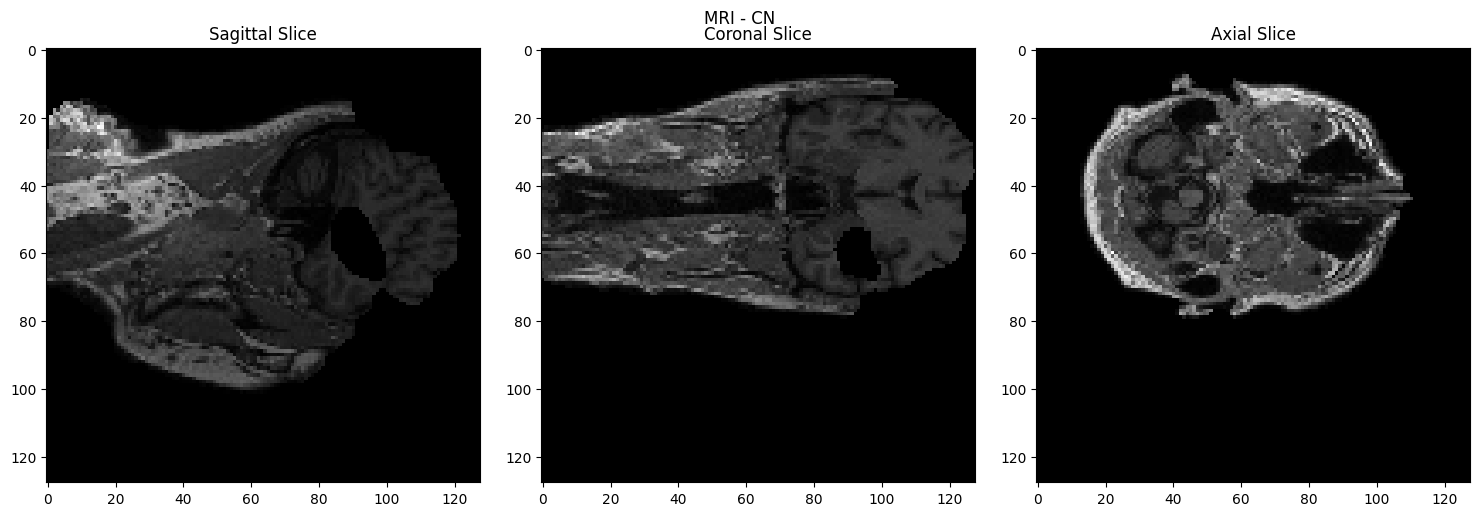

Visualising PET sample:
Image shape: torch.Size([1, 128, 128, 128])


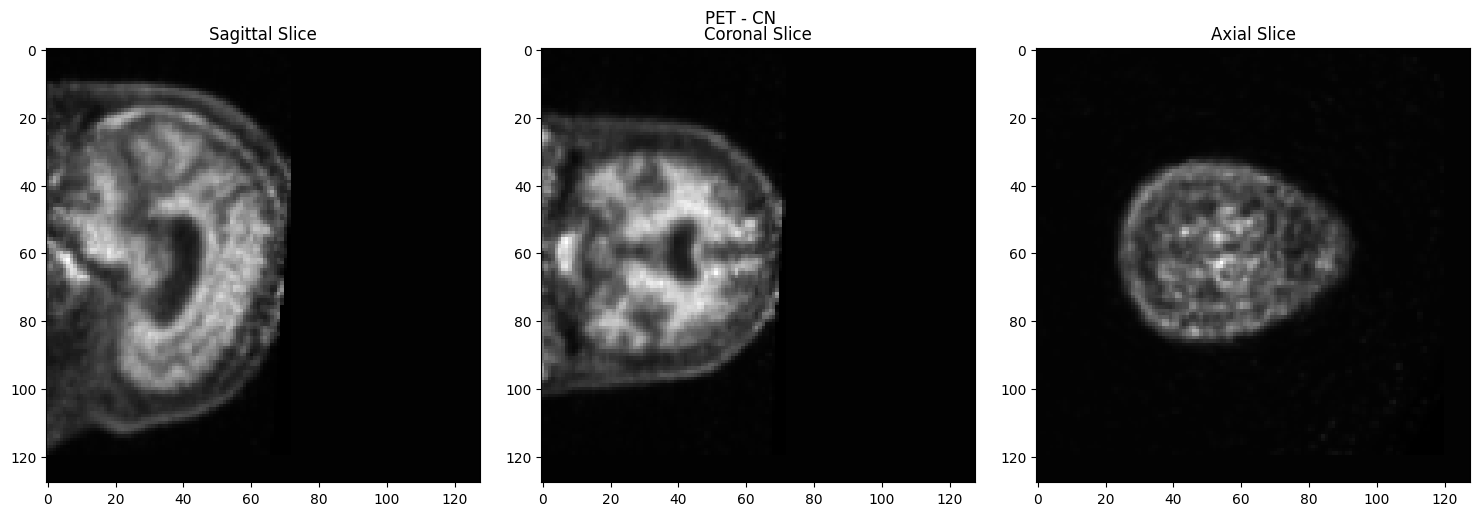

Visualising PET sample:
Image shape: torch.Size([1, 128, 128, 128])


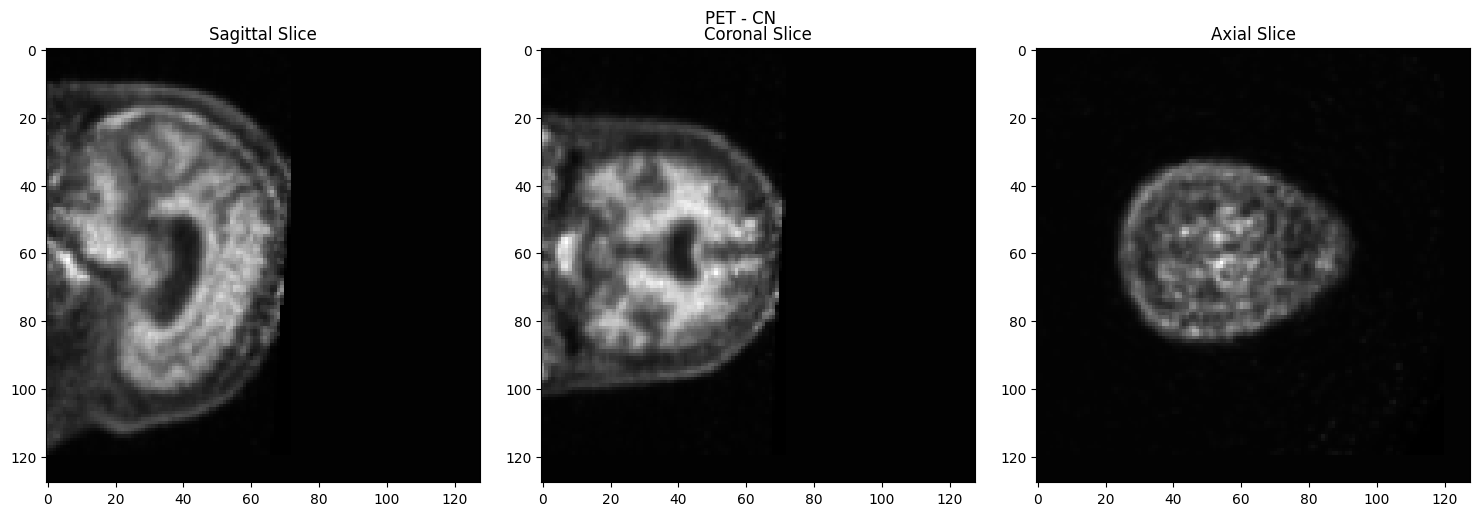

Visualising co-registered sample:
Image shape: torch.Size([1, 128, 128, 128])


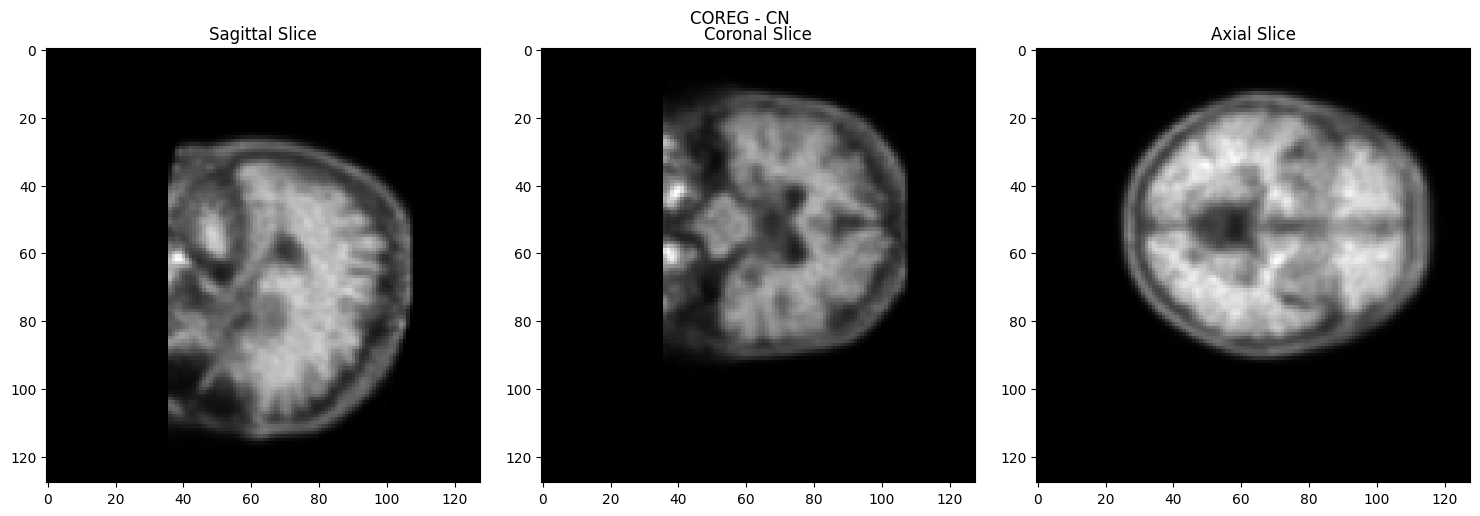

In [ ]:
#Visualise 3D medical images by extracting representative 2D slices for qualitative inspection of MRI, PET, and co-registered scans.
def sampleVisualisation(dataset, idx=0, modality=""):
    sample = dataset[idx]
    image = sample['image']
    label = sample['label']

    #Display basic tensor shape to help diagnose unexpected input dimensions early.
    print(f"Image shape: {image.shape}")

    #Handle standard volumetric formats; channel-first convention is assumed for single-channel data.
    if len(image.shape) == 4 and image.shape[0] == 1:
        volume = image[0]
    #Handle rare formats where channels are last; fallback to first channel.
    elif len(image.shape) == 4 and image.shape[3] == 4:
        volume = image[:, :, :, 0]
    else:
        #Gracefully exit if an unexpected format is encountered to avoid downstream errors.
        print(f"Unexpected image shape: {image.shape}")
        return

    #Extract central slices along each major anatomical plane for informative and consistent visualisation.
    middle_z = volume.shape[0] // 2
    middle_y = volume.shape[1] // 2
    middle_x = volume.shape[2] // 2

    slice_x = volume[middle_z, :, :]
    slice_y = volume[:, middle_y, :]
    slice_z = volume[:, :, middle_x]

    #Plot three orthogonal views to provide spatial context about the brain's internal structure.
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(slice_x, cmap='gray')
    axes[0].set_title(f"Sagittal Slice")

    axes[1].imshow(slice_y, cmap='gray')
    axes[1].set_title(f"Coronal Slice")

    axes[2].imshow(slice_z, cmap='gray')
    axes[2].set_title(f"Axial Slice")

    #Annotate the plots with modality and diagnosis to aid visual comparison across samples.
    fig.suptitle(f"{modality.upper()} - {'AD' if label == 1 else 'CN'}")
    plt.tight_layout()
    plt.show()

#Visually check MRI samples to confirm structural features are correctly captured.
print("Visualising MRI sample:")
sampleVisualisation(dataloaders['mri']['train'].dataset, idx=0, modality="mri")

#Visually check PET samples to verify chemical activity mapping.
print("Visualising PET sample:")
sampleVisualisation(dataloaders['pet']['train'].dataset, idx=0, modality="pet")

#Visua
#Visually check PET samples to verify chemical activity mapping.
print("Visualising PET sample:")
sampleVisualisation(dataloaders['pet']['train'].dataset, idx=0, modality="pet")

#Visually check co-registered samples to ensure combined modalities align correctly.
print("Visualising co-registered sample:")
sampleVisualisation(dataloaders['coreg']['train'].dataset, idx=0, modality="coreg")

**MODEL** BUILDING SINGLE **MODELS**

In [ ]:
#Define a 3D CNN to classify volumetric brain scans while balancing complexity and performance.
class CNN3D(nn.Module):
  #a constructor that runs when you create the model, one input channel as brain scan in greyscale
  #number of classes is two as there are two output classes
  #50% drop out probability to help prevent overfitting
    def __init__(self, input_channels=1, num_classes=2, dropout_rate=0.5):
        super(CNN3D, self).__init__()#tells python to inherit all the standard functions from the nn.module

        #Sequential feature extractor capturing 3D spatial patterns at multiple resolutions.
        self.features = nn.Sequential(
            nn.Conv3d(input_channels, 32, kernel_size=3, padding=1), nn.BatchNorm3d(32), nn.ReLU(inplace=True), nn.MaxPool3d(kernel_size=2),

            nn.Conv3d(32, 64, kernel_size=3, padding=1), nn.BatchNorm3d(64), nn.ReLU(inplace=True), nn.MaxPool3d(kernel_size=2),

            nn.Conv3d(64, 128, kernel_size=3, padding=1), nn.BatchNorm3d(128), nn.ReLU(inplace=True), nn.MaxPool3d(kernel_size=2),)

        #Global spatial aggregation to ensure fixed feature size regardless of input dimensions.
        self.avg_pool = nn.AdaptiveAvgPool3d((1, 1, 1))

        #Classification head designed for compact feature embedding and regularised decision making.
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128, 256), nn.ReLU(inplace=True), nn.Dropout(dropout_rate), nn.Linear(256, num_classes))

    def forward(self, x):
        features = self.features(x)

        pooled = self.avg_pool(features)
        features_flat = torch.flatten(pooled, 1)

        logits = self.classifier(features_flat)

        #Return both logits for classification and intermediate feature vectors for optional feature fusion or analysis.
        return logits, features_flat


In [ ]:
#Early stopping utility to terminate training once validation loss stops improving beyond a threshold.
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0, verbose=False):
        self.patience = patience  #Number of epochs to wait after last improvement before stopping.
        self.min_delta = min_delta  #Minimum change in validation loss to qualify as an improvement.
        self.verbose = verbose  #Enable detailed logging to monitor early stopping behaviour.
        self.counter = 0  #Counter to track how many epochs have passed without improvement.
        self.best_loss = float('inf')  #Track the best validation loss seen so far.
        self.early_stop = False  #Flag to indicate whether early stopping should be triggered.

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0  #Reset counter when a new best loss is found.
        else:
            self.counter += 1  #Increment counter when no improvement.
            if self.verbose:
                print(f"Early stopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
                if self.verbose:
                    print("Early stopping triggered")

#Calculate a range of evaluation metrics to assess model performance beyond simple accuracy.
def calculate_metrics(y_true, y_pred, y_scores=None):
    metrics = {}

    metrics['accuracy'] = accuracy_score(y_true, y_pred)
    metrics['precision'] = precision_score(y_true, y_pred, average='binary')
    metrics['recall'] = recall_score(y_true, y_pred, average='binary')
    metrics['f1'] = f1_score(y_true, y_pred, average='binary')

    #Include AUC score if raw prediction scores are provided for evaluating ranking quality.
    if y_scores is not None:
        metrics['auc'] = roc_auc_score(y_true, y_scores)

    cm = confusion_matrix(y_true, y_pred)
    metrics['tn'], metrics['fp'], metrics['fn'], metrics['tp'] = cm.ravel()

    metrics['sensitivity'] = metrics['recall']  #Sensitivity is equivalent to recall in binary classification.
    metrics['specificity'] = metrics['tn'] / (metrics['tn'] + metrics['fp'])  #Specificity measures true negative rate.

    return metrics

#Track and organise losses, metrics, and learning rates across epochs to support model evaluation and debugging.
class MetricTracker:
    def __init__(self):
        self.train_losses = []  #Store training loss per epoch.
        self.val_losses = []  #Store validation loss per epoch.
        self.train_metrics = []  #Store training metrics (accuracy, precision, etc.) per epoch.
        self.val_metrics = []  #Store validation metrics per epoch.
        self.learning_rates = []  #Track learning rate changes, useful for dynamic LR schedules.

    def update_train(self, loss, metrics, lr):
        self.train_losses.append(loss)
        self.train_metrics.append(metrics)
        self.learning_rates.append(lr)

    def update_val(self, loss, metrics):
        self.val_losses.append(loss)
        self.val_metrics.append(metrics)

In [ ]:
#Train 3D CNN model with tracking, validation, checkpoint saving, and optional learning rate scheduling.
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler=None, num_epochs=10, device='cuda', name="model", checkpoint_dir='./checkpoints'):
    os.makedirs(checkpoint_dir, exist_ok=True)  #Ensure checkpoint directory exists to avoid saving errors later.

    best_val_acc = 0.0  #Track the best validation accuracy to decide when to save model checkpoints.
    best_model = None

    tracker = MetricTracker()  #Store losses and metrics across epochs for post-training analysis.

    print(f"Starting training for {name}...")
    start_time = time.time()

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')

        model.train()  #Set model to training mode to enable dropout and batch norm updates.
        train_loss = 0.0
        train_correct = 0
        train_total = 0
        all_train_labels = []
        all_train_preds = []
        all_train_logits = []

        #Training loop over all batches.
        for batch in tqdm(train_loader, desc="Training"):
            inputs = batch['image'].to(device)
            labels = batch['label'].to(device)

            optimizer.zero_grad()  #Clear previous gradients before backpropagation.

            outputs, _ = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)  #Accumulate batch loss scaled by batch size.
            _, predicted = torch.max(outputs, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

            #Collect predictions and true labels for metric calculation later.
            all_train_labels.extend(labels.cpu().numpy())
            all_train_preds.extend(predicted.cpu().numpy())
            all_train_logits.extend(torch.softmax(outputs, dim=1)[:, 1].detach().cpu().numpy())

        epoch_train_loss = train_loss / train_total
        epoch_train_acc = train_correct / train_total
        epoch_train_metrics = calculate_metrics(np.array(all_train_labels), np.array(all_train_preds), np.array(all_train_logits))

        model.eval()  #Switch to evaluation mode to disable dropout and fix batch norm statistics.
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        all_val_labels = []
        all_val_preds = []
        all_val_logits = []

        #Validation loop without gradient updates for efficiency.
        with torch.no_grad():
            for batch in tqdm(val_loader, desc="Validation"):
                inputs = batch['image'].to(device)
                labels = batch['label'].to(device)

                outputs, _ = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

                all_val_labels.extend(labels.cpu().numpy())
                all_val_preds.extend(predicted.cpu().numpy())
                all_val_logits.extend(torch.softmax(outputs, dim=1)[:, 1].detach().cpu().numpy())

        epoch_val_loss = val_loss / val_total
        epoch_val_acc = val_correct / val_total
        epoch_val_metrics = calculate_metrics(np.array(all_val_labels), np.array(all_val_preds), np.array(all_val_logits))

        tracker.update_train(epoch_train_loss, epoch_train_metrics, optimizer.param_groups[0]['lr'])
        tracker.update_val(epoch_val_loss, epoch_val_metrics)

        #Print current epoch statistics for quick monitoring.
        print(f'Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f}, F1: {epoch_train_metrics["f1"]:.4f}')
        print(f'Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}, F1: {epoch_val_metrics["f1"]:.4f}')

        if scheduler is not None:
            scheduler.step(epoch_val_loss)  #Optionally adjust learning rate based on validation performance.

        #Save model checkpoint if validation accuracy improves.
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            best_model = model.state_dict()

            checkpoint_path = os.path.join(checkpoint_dir, f"{name}_best.pth")
            torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(), 'optimizer_state_dict': optimizer.state_dict(), 'loss': epoch_val_loss, 'accuracy': epoch_val_acc}, checkpoint_path)
            print(f"Saved new best model to {checkpoint_path}")

        print()

    time_elapsed = time.time() - start_time
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val accuracy: {best_val_acc:.4f}')

    model.load_state_dict(best_model)  #Load the best performing model before returning.
    return model, tracker


In [ ]:
#Evaluate a trained model on a test dataset, computing classification metrics and extracting learned features for further analysis.
def test_model(model, dataloader, criterion, device, name):
    model.eval()  #Set model to evaluation mode to disable dropout and batch norm updates.

    running_loss = 0.0
    all_labels = []
    all_preds = []
    all_logits = []
    all_features = []

    print(f"Testing model {name}...")

    #Disable gradient calculation to improve efficiency and reduce memory usage during evaluation.
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=f"Testing {name}"):
            inputs = batch['image'].to(device)
            labels = batch['label'].to(device)

            outputs, features = model(inputs)
            loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)
            logits = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()

            running_loss += loss.item() * inputs.size(0)  #Accumulate total loss for averaging later.
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_logits.extend(logits)
            all_features.extend(features.cpu().numpy())  #Collect intermediate features for potential visualisation or clustering.

    labels_array = np.array(all_labels)
    logits_array = np.array(all_logits)

    binary_preds = (logits_array > 0.5).astype(int)  #Threshold raw logits to create binary predictions for evaluation.

    test_loss = running_loss / len(dataloader.dataset)
    test_metrics = calculate_metrics(labels_array, binary_preds, logits_array)

    #Print detailed evaluation metrics to assess model performance on unseen data.
    print(f'Test Loss: {test_loss:.4f}')
    print(f'Test Accuracy: {test_metrics["accuracy"]:.4f}')
    print(f'Test F1 Score: {test_metrics["f1"]:.4f}')
    print(f'Test Sensitivity: {test_metrics["sensitivity"]:.4f}')
    print(f'Test Specificity: {test_metrics["specificity"]:.4f}')
    print(f'Test AUC: {test_metrics["auc"]:.4f}')

    #Return metrics, feature embeddings, true labels, and prediction scores for further analysis or reporting.
    return test_metrics, np.array(all_features), labels_array, logits_array


In [ ]:
#Plot the training and validation loss, accuracy, F1 score, and AUC to visually assess learning behaviour across epochs.
def plot_training_history(tracker, title, save_path=None):
    plt.figure(figsize=(15, 10))

    #Plot how training loss and validation loss changed after each epoch.
    plt.subplot(2, 2, 1)
    plt.plot(tracker.train_losses, label='Training Loss')
    plt.plot(tracker.val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss over epochs')
    plt.legend()

    #Plot accuracy over epochs.
    plt.subplot(2, 2, 2)
    train_acc = [metrics['accuracy'] for metrics in tracker.train_metrics]
    val_acc = [metrics['accuracy'] for metrics in tracker.val_metrics]
    plt.plot(train_acc, label='Training Accuracy')
    plt.plot(val_acc, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy over epochs')
    plt.legend()

    #Plot F1 scores over epochs.
    plt.subplot(2, 2, 3)
    train_f1 = [metrics['f1'] for metrics in tracker.train_metrics]
    val_f1 = [metrics['f1'] for metrics in tracker.val_metrics]
    plt.plot(train_f1, label='Training F1')
    plt.plot(val_f1, label='Validation F1')
    plt.xlabel('Epochs')
    plt.ylabel('F1 Score')
    plt.title('F1 Score over epochs')
    plt.legend()

    #Plot AUC scores over epochs.
    plt.subplot(2, 2, 4)
    train_auc = [metrics['auc'] for metrics in tracker.train_metrics]
    val_auc = [metrics['auc'] for metrics in tracker.val_metrics]
    plt.plot(train_auc, label='Training AUC')
    plt.plot(val_auc, label='Validation AUC')
    plt.xlabel('Epochs')
    plt.ylabel('AUC')
    plt.title('AUC over epochs')
    plt.legend()

    #Make sure plots don’t overlap.
    #Set a big overall title for the figure.
    plt.tight_layout()
    plt.suptitle(title, fontsize=16)
    plt.subplots_adjust(top=0.9)

    #Optionally save the plot to a file for documentation or reporting.
    if save_path:
        plt.savefig(save_path)
        print(f"Saved training history plot to {save_path}")

    plt.show()

#Plot a confusion matrix to visualise classification performance, highlighting true positives, false positives, false negatives, and true negatives.
def plot_confusion_matrix(y_true, y_pred, classes, title=None, save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))

    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title(title or 'Confusion Matrix')
    plt.colorbar()

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    thresh = cm.max() / 2.
    #Overlay numerical values on the matrix cells, adjusting text color based on background intensity for better readability.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, format(cm[i, j], 'd'),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

    if save_path:
        plt.savefig(save_path)
        print(f"Saved confusion matrix plot to {save_path}")

    plt.show()

Using device: cuda

Training MRI Model...
Starting training for MRI...
Epoch 1/50


Training:   0%|          | 0/141 [00:00<?, ?it/s]

Validation:   0%|          | 0/13 [00:00<?, ?it/s]

Train Loss: 0.6887, Train Acc: 0.4804, F1: 0.5706
Val Loss: 0.6548, Val Acc: 0.4231, F1: 0.5946
Saved new best model to ./checkpoints/MRI_best.pth

Epoch 2/50


Training:   0%|          | 0/141 [00:00<?, ?it/s]

Validation:   0%|          | 0/13 [00:00<?, ?it/s]

... (295 outputs left out)

Testing MRI:   0%|          | 0/18 [00:00<?, ?it/s]

Test Loss: 0.6796
Test Accuracy: 0.6571
Test F1 Score: 0.6471
Test Sensitivity: 0.7333
Test Specificity: 0.6000
Test AUC: 0.7433

Testing PET Model...
Testing model PET...


Testing PET:   0%|          | 0/18 [00:00<?, ?it/s]

Test Loss: 0.3861
Test Accuracy: 0.8571
Test F1 Score: 0.8276
Test Sensitivity: 0.8000
Test Specificity: 0.9000
Test AUC: 0.9200
Saved training history plot to ./plots/mri_training_history.png


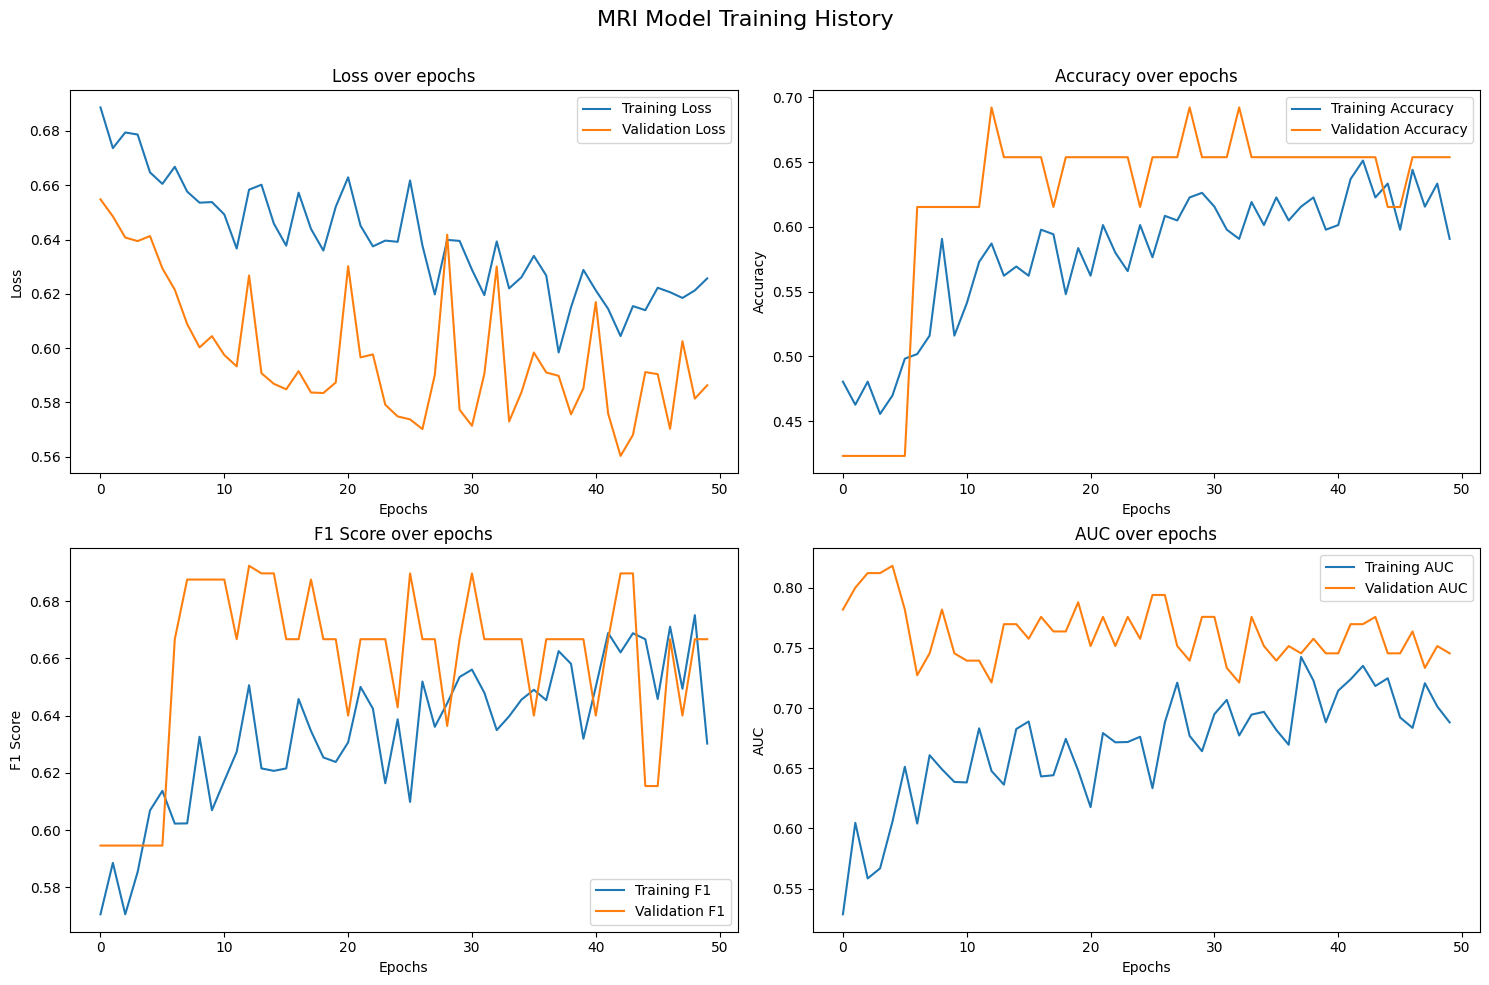

Saved training history plot to ./plots/pet_training_history.png


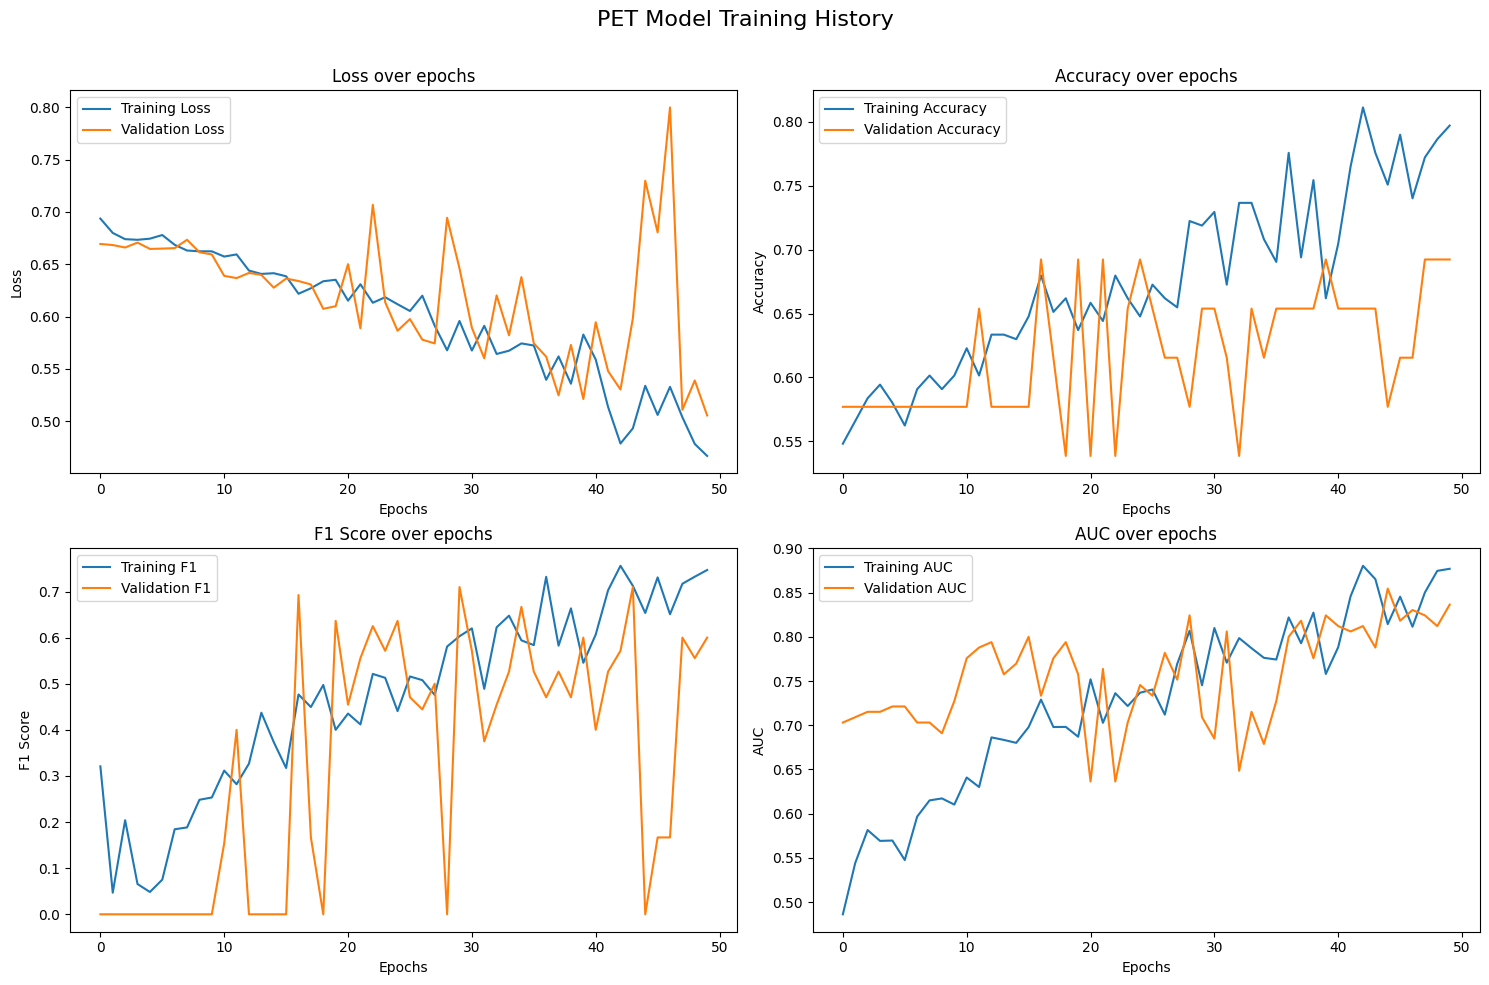

Saved confusion matrix plot to ./plots/mri_confusion_matrix.png


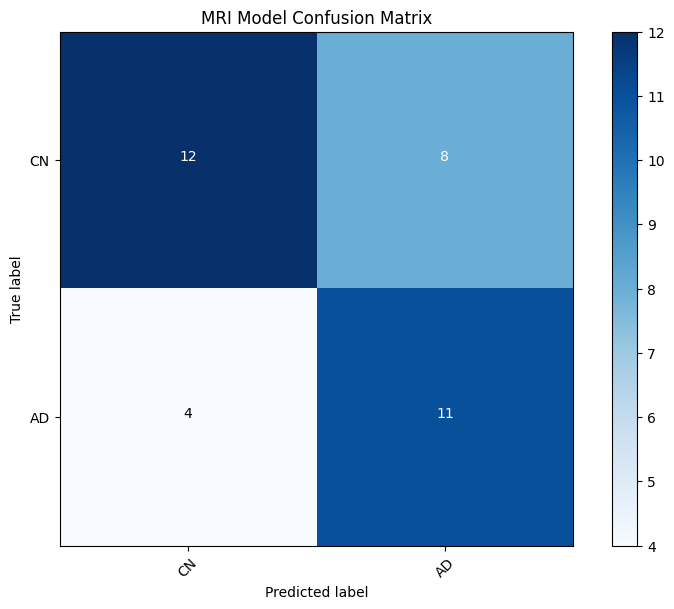

Saved confusion matrix plot to ./plots/pet_confusion_matrix.png


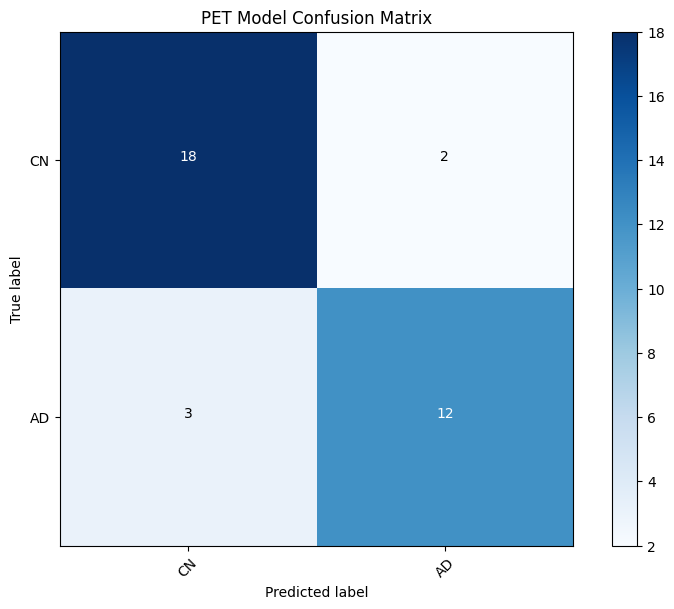

Training and testing completed successfully!
Features saved for late fusion model.


In [ ]:
#Simplified pipeline to independently train and evaluate 3D CNN models for MRI and PET modalities.
def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  #Prefer GPU if available for faster training.
    print(f"Using device: {device}")

    os.makedirs('./checkpoints', exist_ok=True)  #Ensure directories exist for saving checkpoints.
    os.makedirs('./plots', exist_ok=True)  #Create directory for storing training and evaluation plots.

    # learning_rate = 1e-4
    # dropout_rate = 0.5
    # num_epochs = 30

    #NEW PARAMETERS UPON RESULTS
    learning_rate = 3e-5
    weight_decay = 1e-4
    dropout_rate = 0.5 #BACK TO 0.5
    num_epochs = 50

    #Initialise separate models for MRI and PET to allow modality-specific training.
    mri_model = CNN3D(input_channels=1, num_classes=2, dropout_rate=dropout_rate)
    pet_model = CNN3D(input_channels=1, num_classes=2, dropout_rate=dropout_rate)

    mri_model = mri_model.to(device)
    pet_model = pet_model.to(device)


    mri_weights = torch.tensor([0.4, 1.6]).to(device)
    pet_weights = torch.tensor([1.0, 1.0]).to(device)

    #criterion = nn.CrossEntropyLoss() THIS LINE IS REPLACED WITH BELOW

    mri_criterion = nn.CrossEntropyLoss(weight=mri_weights)
    pet_criterion = nn.CrossEntropyLoss(weight=pet_weights)

    #mri_optimizer = optim.Adam(mri_model.parameters(), lr=learning_rate)#OLD
    #pet_optimizer = optim.Adam(pet_model.parameters(), lr=learning_rate)#OLD

    mri_optimizer = optim.Adam(mri_model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    pet_optimizer = optim.Adam(pet_model.parameters(), lr=learning_rate, weight_decay=weight_decay)


    #mri_scheduler = ReduceLROnPlateau(mri_optimizer, mode='min', factor=0.2, patience=3, verbose=True)#OLD
    #pet_scheduler = ReduceLROnPlateau(pet_optimizer, mode='min', factor=0.2, patience=3, verbose=True)#OLD


    #Dynamically adjust learning rate if validation loss stagnates to improve convergence.
    mri_scheduler = ReduceLROnPlateau(mri_optimizer, mode='min', factor=0.5, patience=6, min_lr=1e-6, verbose=True)
    pet_scheduler = ReduceLROnPlateau(pet_optimizer, mode='min', factor=0.5, patience=6, min_lr=1e-6, verbose=True)

    print("\nTraining MRI Model...")
    mri_model, mri_tracker = train_model(
        model=mri_model,
        train_loader=dataloaders['mri']['train'],
        val_loader=dataloaders['mri']['val'],
        #criterion=criterion,
        criterion=mri_criterion,
        optimizer=mri_optimizer,
        scheduler=mri_scheduler,
        num_epochs=num_epochs,
        device=device,
        name="MRI"
    )

    print("\nTraining PET Model...")
    pet_model, pet_tracker = train_model(
        model=pet_model,
        train_loader=dataloaders['pet']['train'],
        val_loader=dataloaders['pet']['val'],
        #criterion=criterion,
        criterion=pet_criterion,
        optimizer=pet_optimizer,
        scheduler=pet_scheduler,
        num_epochs=num_epochs,
        device=device,
        name="PET"
    )

    print("\nTesting MRI Model...")
    mri_test_metrics, mri_features, mri_labels, mri_scores = test_model(
        model=mri_model,
        dataloader=dataloaders['mri']['test'],
        #criterion=criterion,
        criterion=mri_criterion,
        device=device,
        name="MRI"
    )

    print("\nTesting PET Model...")
    pet_test_metrics, pet_features, pet_labels, pet_scores = test_model(
        model=pet_model,
        dataloader=dataloaders['pet']['test'],
        #criterion=criterion,
        criterion=pet_criterion,
        device=device,
        name="PET"
    )

    #Plot training history to visualise learning curves for loss, accuracy, F1, and AUC.
    plot_training_history(
        mri_tracker,
        title="MRI Model Training History",
        save_path="./plots/mri_training_history.png"
    )

    plot_training_history(
        pet_tracker,
        title="PET Model Training History",
        save_path="./plots/pet_training_history.png"
    )

    #Plot confusion matrices to inspect true vs predicted class distributions.
    plot_confusion_matrix(
        mri_labels,
        (mri_scores > 0.5).astype(int),
        classes=['CN', 'AD'],
        title='MRI Model Confusion Matrix',
        save_path='./plots/mri_confusion_matrix.png'
    )

    plot_confusion_matrix(
        pet_labels,
        (pet_scores > 0.5).astype(int),
        classes=['CN', 'AD'],
        title='PET Model Confusion Matrix',
        save_path='./plots/pet_confusion_matrix.png'
    )

    os.makedirs('./features', exist_ok=True)  #Directory for saving extracted features for later fusion or analysis.
    np.save('./features/mri_features.npy', mri_features)
    np.save('./features/pet_features.npy', pet_features)
    np.save('./features/mri_labels.npy', mri_labels)
    np.save('./features/pet_labels.npy', pet_labels)

    print("Training and testing completed successfully!")
    print("Features saved for late fusion model.")

if __name__ == "__main__":
    main()